# 01 펌프 데이터 파일 구조와 결측치 진단



## 1. 파일 구조 확인

### 1-1. 원본 파일 불러오기

저장소 최상위나 `notebooks/`에서 실행할 수 있습니다. 경로는 기존 결측 진단 모듈과 같은 기준으로 찾습니다.

In [ ]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# 현재 작업 폴더에서 위로 올라가며 팀 저장소를 찾습니다.
current_dir = Path.cwd()
project_root = next(
    (
        folder for folder in (current_dir, *current_dir.parents)
        if (folder / "src" / "pump_missingness_audit.py").is_file()
    ),
    None,
)
if project_root is None:
    raise FileNotFoundError("kkobugi 저장소나 notebooks 폴더에서 커널을 실행하세요.")

sys.path.insert(0, str(project_root))
from src.plot_style import use_portable_style
from src.pump_missingness_audit import (
    audit_missingness, default_source, read_sensor_data,
)

# 모든 OS에서 같은 글꼴과 같은 PNG가 나오도록 설정합니다.
use_portable_style()

source = default_source()
raw = read_sensor_data(source)
sensor_columns = [column for column in raw if column.startswith("sensor_")]
print(f"입력 파일: {source.relative_to(project_root).as_posix()}")
print(f"원본 {len(raw):,}행 × {len(raw.columns)}열 · 센서 {len(sensor_columns)}개")
display(raw.loc[:, ["timestamp", *sensor_columns[:4], "machine_status"]].head(4))

입력 파일: data/sensor.csv
원본 220,320행 × 55열 · 센서 52개


,timestamp,sensor_00,sensor_01,sensor_02,sensor_03,machine_status
0,2018-04-01 00:00:00,2.465394,47.09201,53.2118,46.310760,NORMAL
1,2018-04-01 00:01:00,2.465394,47.09201,53.2118,46.310760,NORMAL
2,2018-04-01 00:02:00,2.444734,47.35243,53.2118,46.397570,NORMAL
3,2018-04-01 00:03:00,2.460474,47.09201,53.1684,46.397568,NORMAL


### 1-2. 열의 역할과 시간축 확인

행 번호는 원본 대조에 사용합니다. `timestamp`는 시간 순서를, `machine_status`는 원본 설비 상태를 확인하는 열입니다. 시각 자체가 빠진 경우와 센서값이 비어 있는 경우를 구분합니다.

In [ ]:
timestamps = pd.to_datetime(raw["timestamp"], errors="coerce")
ordered_times = timestamps.dropna().sort_values()
missing_timestamps = len(pd.date_range(ordered_times.iloc[0], ordered_times.iloc[-1], freq="min"))
missing_timestamps -= ordered_times.nunique()

schema = pd.DataFrame({
    "열": ["timestamp", "machine_status", "sensor_*", "그 외"],
    "자료형": [
        str(raw["timestamp"].dtype),
        str(raw["machine_status"].dtype),
        ", ".join(sorted({str(raw[column].dtype) for column in sensor_columns})),
        ", ".join(str(raw[column].dtype) for column in raw if column not in [*sensor_columns, "timestamp", "machine_status"]),
    ],
    "열 수": [1, 1, len(sensor_columns), len(raw.columns) - len(sensor_columns) - 2],
})
display(schema)
print(f"기록 기간: {ordered_times.iloc[0]} ~ {ordered_times.iloc[-1]}")
print(f"파싱 불가 {timestamps.isna().sum():,}행 · 중복 {timestamps.dropna().duplicated().sum():,}행 · 시각 누락 {missing_timestamps:,}분")
display(raw["machine_status"].value_counts(dropna=False).to_frame("원본 상태별 행 수"))

,열,자료형,열 수
0,timestamp,str,1
1,machine_status,str,1
2,sensor_*,float64,52
3,그 외,int64,1


기록 기간: 2018-04-01 00:00:00 ~ 2018-08-31 23:59:00
파싱 불가 0행 · 중복 0행 · 시각 누락 0분


,원본 상태별 행 수
machine_status,
NORMAL,205836
RECOVERING,14477
BROKEN,7


## 2. 결측치 확인

전체 기록을 하나로 집계하고 원본 설비 상태별로 결측 양상을 확인합니다.

### 2-1. 전체 센서가 비어 있는 행 찾기

원본 시각, CSV 레코드 번호, 첫 번째 열의 원본 행 번호를 함께 확인합니다. CSV 레코드 번호에는 헤더 한 줄이 포함됩니다.

In [ ]:
# 진단 모듈에서 전체 기간 기준 요약과 상세 표를 가져옵니다.
report = audit_missingness(source, min_gap=60, split_by_period=False)
display(report["all_missing_rows"])
display(report["by_status"])

,CSV 레코드 번호,원본 행 번호,machine_status
timestamp,,,
2018-04-27 17:48:00,38510,38508,NORMAL
2018-04-27 17:49:00,38511,38509,NORMAL
2018-04-27 17:50:00,38512,38510,NORMAL
2018-04-27 17:51:00,38513,38511,NORMAL
2018-04-27 17:52:00,38514,38512,NORMAL
2018-04-27 17:53:00,38515,38513,NORMAL
2018-04-27 17:54:00,38516,38514,NORMAL
2018-04-27 17:55:00,38517,38515,NORMAL
2018-07-11 09:12:00,145994,145992,NORMAL


,전체 행,센서 전체 결측,일부 결측(전 구간 결측 센서 제외)
상태,,,
BROKEN,7,0,2
NORMAL,205836,11,89692
RECOVERING,14477,0,11512


### 2-2. 센서별 장기 결측 확인

장기 결측 상세 표는 60분 이상 공백 중 가장 긴 12개를 보여줍니다. 그래프는 `sensor_15`를 포함해 최장 공백이 큰 센서 8개를 일 단위로 비교합니다.

,결측 건수,결측률(%),최장 결측(분)
sensor_15,220320,100.000,220320
sensor_50,77017,34.957,76996
sensor_51,15383,6.982,15356
sensor_00,10208,4.633,6076
sensor_07,5451,2.474,4668
sensor_08,5107,2.318,4227
sensor_06,4798,2.178,4299
sensor_09,4595,2.086,4212
sensor_01,369,0.167,200
sensor_30,261,0.118,239


,센서,시작,종료,연속 결측(분)
0,sensor_15,2018-04-01 00:00:00,2018-08-31 23:59:00,220320
1,sensor_50,2018-07-09 12:44:00,2018-08-31 23:59:00,76996
2,sensor_51,2018-06-20 07:58:00,2018-06-30 23:53:00,15356
3,sensor_00,2018-06-29 09:19:00,2018-07-03 14:34:00,6076
4,sensor_07,2018-06-30 09:18:00,2018-07-03 15:05:00,4668
5,sensor_06,2018-06-30 15:27:00,2018-07-03 15:05:00,4299
6,sensor_08,2018-06-30 15:45:00,2018-07-03 14:11:00,4227
7,sensor_09,2018-06-30 16:00:00,2018-07-03 14:11:00,4212
8,sensor_00,2018-04-18 00:31:00,2018-04-20 04:13:00,3103
9,sensor_00,2018-04-12 22:00:00,2018-04-13 13:15:00,916


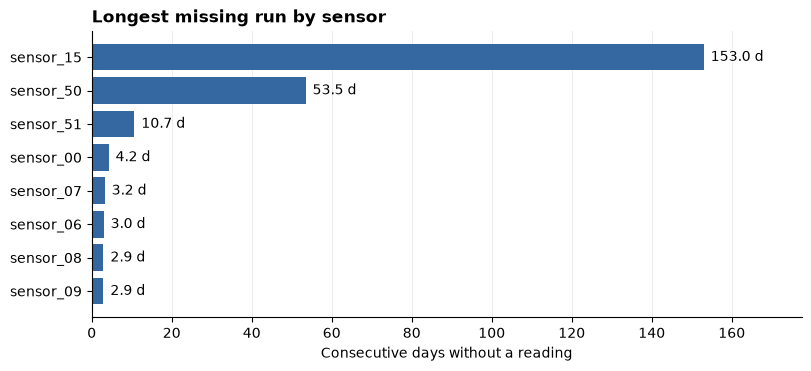

In [ ]:
sensor_missing = report["by_sensor"]
display(sensor_missing.head(12).round(3))
display(report["long_gaps"].loc[:, ["센서", "시작", "종료", "연속 결측(분)"]].head(12))

gap_days = (
    sensor_missing["최장 결측(분)"]
    .nlargest(8)
    .div(1440)
    .sort_values()
)
fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
bars = ax.barh(gap_days.index, gap_days, color="#3568a0")
ax.bar_label(bars, fmt="%.1f d", padding=5)
ax.set_xlim(0, max(gap_days.max() * 1.16, 1))
ax.set_title("Longest missing run by sensor", loc="left", fontweight="bold")
ax.set_xlabel("Consecutive days without a reading")
ax.grid(axis="x", alpha=0.22)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

### 2-3. 원본 52개 센서별 결측

`sensor_00`부터 `sensor_51`까지 모든 센서를 번호순으로 표시합니다. 결측률의 분모는 전체 원본 행 수입니다. 센서별 시계열 PNG는 저장소의 `figures/sensor_missingness/`에 있습니다.

In [ ]:
# 진단 모듈이 반환한 원본 센서 전체의 결측을 표시합니다.
sensor_details = report["sensor_details"]
summary = report["summary"]
print(f"결측이 한 번이라도 있는 센서: {sensor_details['결측 건수'].gt(0).sum()} / {summary['sensor_count']}개")
print(f"52개 센서 중 하나 이상 결측인 행: {summary['selected_missing_rows']:,} / {summary['row_count']:,}행")
with pd.option_context("display.max_rows", len(sensor_details)):
    display(sensor_details.round(3))

결측이 한 번이라도 있는 센서: 52 / 52개
52개 센서 중 하나 이상 결측인 행: 220,320 / 220,320행


,결측 건수,결측률(%),최장 결측(분)
sensor_00,10208,4.633,6076
sensor_01,369,0.167,200
sensor_02,19,0.009,8
sensor_03,19,0.009,8
sensor_04,19,0.009,8
sensor_05,19,0.009,8
sensor_06,4798,2.178,4299
sensor_07,5451,2.474,4668
sensor_08,5107,2.318,4227
sensor_09,4595,2.086,4212


### 2-4. 결측 요약

- 원본은 220,320행, 센서는 52개입니다. 기록은 1분 간격으로 이어지고 시각 자체가 빠진 곳은 없습니다.
- 센서 52개 모두 한 번 이상 결측이 있습니다. `sensor_15`는 220,320행 모두 결측입니다.
- 전 구간이 결측인 `sensor_15`의 영향으로 모든 행에 최소 하나의 결측이 있습니다. 나머지 51개 센서에 한정하면 결측이 있는 행은 101,217행(45.94%)입니다.
- 원본 센서 52개가 동시에 비어 있는 행은 11개입니다. 정확한 시각과 행 번호는 2-1에서 확인할 수 있습니다.